# Objective Quest DATAQUEST 5.0 — V6: Error-Centric Ordinal Learning

V6 is built from the evidence accumulated in V1–V5 and from the organizer clarification that every hyperparameter, threshold, feature, and modeling choice must be reproducible and defensible from the supplied competition data.

## V6 thesis

The strongest remaining legal direction is **not more features** and **not another generic model family**. V1–V5 repeatedly showed a ceiling around QWK 0.48, highly stable global feature importance, near-zero residual learnability, and a dominant error mode at the adjacent `1 ↔ 2` boundary.

V6 therefore combines:

1. a compact **V2-lite anchor** (LightGBM + XGBoost + raw-categorical CatBoost),
2. **OOF soft-target distillation** to reduce variance/noise on ambiguous adjacent labels,
3. **OOF difficulty weighting** to spend gradient on repeatedly hard rows without oversampling,
4. a true **CORN-style conditional ordinal model**,
5. error-cohort EDA focused on `true1/pred2` and `true2/pred1`,
6. multi-probe gates before expensive candidate full-CV,
7. fully cross-fitted final blending and threshold calibration.

No external data, source-dataset reconstruction, leaderboard probing, hardcoded test labels, or manual row mapping is used.

**Important:** no notebook can honestly guarantee a leaderboard score before execution. This notebook uses a hard `TOP1_TARGET = 0.61541` diagnostic, but it will only mark a model as a Top-1 candidate if the honest grouped cross-fitted score actually reaches that value.

## Pipeline

1. Problem Understanding  
2. Preprocessing  
3. Fitting for Explainable AI  
4. EDA + Error-Cohort EDA  
5. Feature Engineering
   - Discretization
   - Feature Selection
   - Feature Creation
   - Clipping / sentinel separation
   - Feature Encoding
6. Modeling
7. Evaluation

Tabular pitfalls explicitly respected:

- adding more features ≠ better score;
- no feature scaling for tree models;
- no SMOTE / random oversampling;
- missing values remain native wherever the model supports them;
- sample weighting is derived only from **inner OOF errors**, not class balancing;
- feature and model selection is train/CV-derived and reproducible.

In [1]:
import os, gc, json, math, random, warnings
from pathlib import Path
from dataclasses import dataclass, asdict
from itertools import combinations

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import StratifiedGroupKFold, train_test_split
from sklearn.metrics import cohen_kappa_score, mean_squared_error, roc_auc_score, confusion_matrix
from sklearn.inspection import permutation_importance
from scipy.optimize import minimize

import lightgbm as lgb
import xgboost as xgb
from catboost import CatBoostRegressor

warnings.filterwarnings('ignore')
np.set_printoptions(suppress=True, precision=6)
pd.set_option('display.max_columns', 220)
pd.set_option('display.width', 190)

print('Environment ready')
print('LightGBM', lgb.__version__, '| XGBoost', xgb.__version__)

Environment ready
LightGBM 4.6.0 | XGBoost 3.2.0


In [2]:
@dataclass
class Config:
    COMPETITION_NAME: str = 'Objective Quest DATAQUEST 5.0'
    VERSION: str = 'v6_error_centric_ordinal'
    TARGET: str = 'life_satisfaction'
    ID_COL: str = 'id'
    HOUSEHOLD_COL: str = 'household_id'
    TRAIN_FILE: str = 'train_final.csv'
    TEST_FILE: str = 'test_final.csv'
    DICT_FILE: str = 'data_dictionary.csv'
    SAMPLE_FILE: str = 'sample_submission.csv'

    SEED: int = 42
    N_FOLDS: int = 5
    INNER_FOLDS: int = 3
    PROBE_FOLDS: tuple = (0, 2, 3)
    USE_GPU: bool = True
    CAT_DEVICES: str = '0:1'

    # Compact feature budget. V1 worked with ~143 features; V2 feature explosion was not beneficial.
    FINAL_FEATURE_BUDGET: int = 140
    FS_ESTIMATORS: int = 1000
    FS_EARLY_STOPPING: int = 80

    # Conservative tree configurations. Early stopping determines effective complexity.
    LGB_N_ESTIMATORS: int = 4200
    XGB_N_ESTIMATORS: int = 4200
    CAT_ITERATIONS: int = 4200
    LEARNING_RATE: float = 0.025
    EARLY_STOPPING: int = 180
    VERBOSE: int = 500
    CAT_MAX_UNIQUE: int = 50

    # Candidate grids. All choices are selected on inner train/calibration only.
    DISTILL_LAMBDA_GRID: tuple = (0.55, 0.70, 0.82, 0.92)
    DIFFICULTY_ALPHA_GRID: tuple = (0.35, 0.70, 1.10, 1.50)
    DIFFICULTY_MAX_WEIGHT: float = 2.75
    BLEND_ALPHA_GRID: tuple = (0.0, 0.10, 0.20, 0.30, 0.40, 0.55, 0.70, 0.85, 1.0)

    # Probe gate: expensive full CV is reserved for evidence that repeats across folds.
    PROMOTE_MIN_MEAN_GAIN: float = 0.0020
    PROMOTE_MIN_WINS: int = 2
    DIAGNOSTIC_FULLCV_MIN_GAIN: float = 0.0008

    TOP1_TARGET: float = 0.61541

    EXPECTED_TRAIN_ROWS: int = 95609
    EXPECTED_TEST_ROWS: int = 23902
    EXPECTED_UNIQUE_TEST_IDS: int = 23666

CFG = Config()
CFG.OUTPUT_DIR = Path('/kaggle/working/oqdq5_v6')
CFG.OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
print(asdict(CFG))

{'COMPETITION_NAME': 'Objective Quest DATAQUEST 5.0', 'VERSION': 'v6_error_centric_ordinal', 'TARGET': 'life_satisfaction', 'ID_COL': 'id', 'HOUSEHOLD_COL': 'household_id', 'TRAIN_FILE': 'train_final.csv', 'TEST_FILE': 'test_final.csv', 'DICT_FILE': 'data_dictionary.csv', 'SAMPLE_FILE': 'sample_submission.csv', 'SEED': 42, 'N_FOLDS': 5, 'INNER_FOLDS': 3, 'PROBE_FOLDS': (0, 2, 3), 'USE_GPU': True, 'CAT_DEVICES': '0:1', 'FINAL_FEATURE_BUDGET': 140, 'FS_ESTIMATORS': 1000, 'FS_EARLY_STOPPING': 80, 'LGB_N_ESTIMATORS': 4200, 'XGB_N_ESTIMATORS': 4200, 'CAT_ITERATIONS': 4200, 'LEARNING_RATE': 0.025, 'EARLY_STOPPING': 180, 'VERBOSE': 500, 'CAT_MAX_UNIQUE': 50, 'DISTILL_LAMBDA_GRID': (0.55, 0.7, 0.82, 0.92), 'DIFFICULTY_ALPHA_GRID': (0.35, 0.7, 1.1, 1.5), 'DIFFICULTY_MAX_WEIGHT': 2.75, 'BLEND_ALPHA_GRID': (0.0, 0.1, 0.2, 0.3, 0.4, 0.55, 0.7, 0.85, 1.0), 'PROMOTE_MIN_MEAN_GAIN': 0.002, 'PROMOTE_MIN_WINS': 2, 'DIAGNOSTIC_FULLCV_MIN_GAIN': 0.0008, 'TOP1_TARGET': 0.61541, 'EXPECTED_TRAIN_ROWS': 9560

## Data loading and reproducibility audit

In [3]:
def locate_data_dir():
    roots = [Path('/kaggle/input'), Path('/mnt/data'), Path('.')]
    required = [CFG.TRAIN_FILE, CFG.TEST_FILE, CFG.SAMPLE_FILE]
    for root in roots:
        if not root.exists():
            continue
        candidates = [root, root/'oq-dq-5', root/'competitions'/'oq-dq-5']
        if root.name == 'input':
            candidates += [p for p in root.iterdir() if p.is_dir()]
        for d in candidates:
            if d.is_dir() and all((d/f).exists() for f in required):
                return d
        for p in root.rglob(CFG.TRAIN_FILE):
            d = p.parent
            if all((d/f).exists() for f in required):
                return d
    raise FileNotFoundError('Could not locate competition CSV files.')

DATA_DIR = locate_data_dir()
print('DATA_DIR:', DATA_DIR)

train = pd.read_csv(DATA_DIR / CFG.TRAIN_FILE, low_memory=False)
test = pd.read_csv(DATA_DIR / CFG.TEST_FILE, low_memory=False)
sample = pd.read_csv(DATA_DIR / CFG.SAMPLE_FILE, low_memory=False)
data_dict = pd.read_csv(DATA_DIR / CFG.DICT_FILE, low_memory=False) if (DATA_DIR / CFG.DICT_FILE).exists() else pd.DataFrame()

assert len(train) == CFG.EXPECTED_TRAIN_ROWS, train.shape
assert len(test) == CFG.EXPECTED_TEST_ROWS, test.shape
assert CFG.TARGET in train.columns and CFG.TARGET not in test.columns
assert list(test.columns) == [c for c in train.columns if c != CFG.TARGET]
assert set(np.unique(train[CFG.TARGET].dropna().astype(int))) == {1,2,3,4}

y = train[CFG.TARGET].astype(int).to_numpy()
groups = train[CFG.ID_COL].astype(str).to_numpy()

print('train', train.shape, 'test', test.shape, 'sample', sample.shape)
print('train unique id:', train[CFG.ID_COL].nunique(), '| test unique id:', test[CFG.ID_COL].nunique())
print('target counts:', train[CFG.TARGET].value_counts().sort_index().to_dict())

DATA_DIR: /kaggle/input/competitions/oq-dq-5
train (95609, 179) test (23902, 178) sample (23902, 2)
train unique id: 94663 | test unique id: 23666
target counts: {1: 42968, 2: 48189, 3: 3559, 4: 893}


In [4]:
# Submission-key audit from supplied files only.
# In train, duplicate IDs have one consistent target and duplicate feature rows.
def duplicate_id_audit(df, has_target=False):
    counts = df[CFG.ID_COL].value_counts()
    dup_ids = counts[counts > 1].index
    rows = df[df[CFG.ID_COL].isin(dup_ids)].copy()
    out = {
        'n_rows': int(len(df)),
        'n_unique_ids': int(df[CFG.ID_COL].nunique()),
        'n_duplicate_ids': int(len(dup_ids)),
    }
    feature_cols = [c for c in test.columns if c != CFG.ID_COL]
    if len(rows):
        # Check every repeated ID has identical feature payload after excluding ID.
        nunique_per_id = rows.groupby(CFG.ID_COL)[feature_cols].nunique(dropna=False).max(axis=1)
        out['all_duplicate_ids_feature_identical'] = bool((nunique_per_id <= 1).all())
        if has_target:
            out['all_duplicate_ids_target_consistent'] = bool((rows.groupby(CFG.ID_COL)[CFG.TARGET].nunique() <= 1).all())
    return out

submission_audit = {
    'train': duplicate_id_audit(train, True),
    'test': duplicate_id_audit(test, False),
    'sample_rows': int(len(sample)),
    'sample_id_matches_test_feature_id_rowwise': bool(len(sample)==len(test) and np.array_equal(sample['id'].to_numpy(), test[CFG.ID_COL].to_numpy())),
}
print(json.dumps(submission_audit, indent=2))

# The competition test contains repeated respondent IDs with identical feature payloads.
# V6 therefore produces one prediction per unique test respondent by averaging continuous row scores before thresholding.
assert test[CFG.ID_COL].nunique() == CFG.EXPECTED_UNIQUE_TEST_IDS
assert submission_audit['train'].get('all_duplicate_ids_target_consistent', False)
assert submission_audit['test'].get('all_duplicate_ids_feature_identical', False)

{
  "train": {
    "n_rows": 95609,
    "n_unique_ids": 94663,
    "n_duplicate_ids": 946,
    "all_duplicate_ids_feature_identical": true,
    "all_duplicate_ids_target_consistent": true
  },
  "test": {
    "n_rows": 23902,
    "n_unique_ids": 23666,
    "n_duplicate_ids": 236,
    "all_duplicate_ids_feature_identical": true
  },
  "sample_rows": 23902,
  "sample_id_matches_test_feature_id_rowwise": false
}


# 1. Problem Understanding

In [5]:
def qwk(y_true, y_pred):
    return float(cohen_kappa_score(np.asarray(y_true, dtype=int), np.asarray(y_pred, dtype=int), weights='quadratic'))

def apply_thresholds(pred, thresholds):
    t = np.sort(np.asarray(thresholds, dtype=float))
    return np.digitize(np.asarray(pred, dtype=float), t) + 1

def optimize_thresholds(y_true, pred, init=(1.55,2.03,2.53), maxiter=350):
    y_true = np.asarray(y_true, dtype=int)
    pred = np.asarray(pred, dtype=float)
    def objective(t):
        tt = np.sort(np.asarray(t,float))
        if tt[0] < 1.0 or tt[-1] > 4.0 or np.min(np.diff(tt)) < 0.025:
            return 10.0
        return -qwk(y_true, apply_thresholds(pred, tt))
    res = minimize(objective, np.asarray(init,float), method='Nelder-Mead',
                   options={'maxiter':maxiter,'xatol':1e-5,'fatol':1e-6})
    t = np.sort(res.x)
    return t, -objective(t)

def boundary_auc(y_true, score):
    y_true=np.asarray(y_true); score=np.asarray(score,float)
    out={}
    for cut in (1,2,3):
        try: out[f'auc_gt{cut}']=float(roc_auc_score((y_true>cut).astype(int),score))
        except Exception: out[f'auc_gt{cut}']=np.nan
    mask=np.isin(y_true,[1,2])
    try: out['auc_1_vs_2']=float(roc_auc_score((y_true[mask]==2).astype(int),score[mask]))
    except Exception: out['auc_1_vs_2']=np.nan
    return out

def rmse(y_true,pred):
    return float(mean_squared_error(np.asarray(y_true,float),np.asarray(pred,float))**0.5)

sgkf = StratifiedGroupKFold(n_splits=CFG.N_FOLDS, shuffle=True, random_state=CFG.SEED)
folds = list(sgkf.split(train, y, groups=groups))
fold_id = np.full(len(train), -1, dtype=np.int8)
for f,(_,va) in enumerate(folds): fold_id[va]=f
print('Fold sizes:', pd.Series(fold_id).value_counts().sort_index().to_dict())

Fold sizes: {0: 19130, 1: 19134, 2: 19113, 3: 19125, 4: 19107}


,count,share
life_satisfaction,,
1,42968,0.449414
2,48189,0.504022
3,3559,0.037225
4,893,0.009340


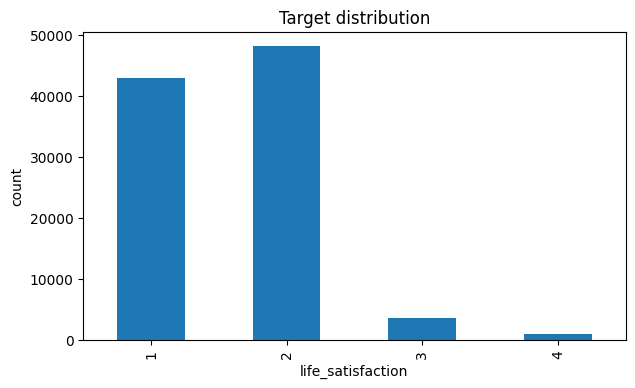

Classes 1+2 share: 0.9534353460448284


In [6]:
target_dist = train[CFG.TARGET].value_counts(normalize=True).sort_index().rename('share')
display(pd.DataFrame({'count':train[CFG.TARGET].value_counts().sort_index(), 'share':target_dist}))

fig,ax=plt.subplots(figsize=(7,4))
train[CFG.TARGET].value_counts().sort_index().plot(kind='bar',ax=ax)
ax.set_title('Target distribution')
ax.set_xlabel('life_satisfaction')
ax.set_ylabel('count')
plt.show()

print('Classes 1+2 share:', float((train[CFG.TARGET].isin([1,2])).mean()))

# 2. Preprocessing

In [7]:
# Continuous-looking fields chosen only from supplied column names.
# Tail sentinels are inferred from TRAIN value gaps, not from external codebooks.
CONTINUOUS_CANDIDATES = [
    'height_inches','weight_pounds','age','hours_worked_per_week','days_missed_work',
    'income_to_poverty_ratio'
]

def infer_tail_sentinels(series, min_gap=8.0, min_gap_ratio=8.0, max_tail_values=8):
    s=pd.to_numeric(series,errors='coerce').dropna()
    vals=np.sort(s.unique())
    if len(vals)<4: return []
    gaps=np.diff(vals)
    positive=gaps[gaps>0]
    if len(positive)==0: return []
    typical=float(np.median(positive))
    i=int(np.argmax(gaps)); gap=float(gaps[i])
    tail=vals[i+1:]
    if gap < min_gap: return []
    if typical>0 and gap/typical < min_gap_ratio: return []
    if len(tail)>max_tail_values: return []
    return [float(v) for v in tail]

SENTINEL_MAP={}
sentinel_audit=[]
for c in CONTINUOUS_CANDIDATES:
    if c in train.columns:
        vals=infer_tail_sentinels(train[c])
        SENTINEL_MAP[c]=vals
        sentinel_audit.append({
            'feature':c,'inferred_tail_values':vals,
            'train_support':int(pd.to_numeric(train[c],errors='coerce').isin(vals).sum()) if vals else 0,
            'test_support':int(pd.to_numeric(test[c],errors='coerce').isin(vals).sum()) if vals else 0,
        })
sentinel_audit=pd.DataFrame(sentinel_audit)
display(sentinel_audit)

,feature,inferred_tail_values,train_support,test_support
0,height_inches,"[96.0, 97.0, 98.0, 99.0]",6166,1520
1,weight_pounds,"[996.0, 997.0, 999.0]",7484,1834
2,age,"[97.0, 99.0]",186,47
3,hours_worked_per_week,[990.0],482,133
4,days_missed_work,"[997.0, 998.0, 999.0]",459,106
5,income_to_poverty_ratio,[110.0],485,120


In [8]:
REDUNDANT_DROP = ['data_year','interview_quarter','food_security_3cat']

FUNCTIONAL_DIFFICULTY_COLS = [
    'difficulty_walking_steps','difficulty_walking_short','difficulty_walking_medium',
    'difficulty_climbing_steps','difficulty_using_hands','difficulty_raising_arm',
    'difficulty_self_care','difficulty_communicating','difficulty_remembering',
    'difficulty_errands_alone','difficulty_social_activities',
]
CHRONIC_CONDITION_COLS = [
    'hypertension_ever','high_cholesterol_ever','heart_disease_ever','heart_attack_ever',
    'angina_ever','stroke_ever','asthma_ever','diabetes_ever','prediabetes_ever',
    'cancer_ever','lung_disease_ever','arthritis_ever','dementia_ever','chronic_fatigue_ever',
]
COST_BARRIER_COLS = [
    'trouble_paying_medical_bills','delayed_care_due_to_cost','skipped_care_due_to_cost',
    'skipped_medication_to_save_money','took_less_medication_to_save_money',
    'delayed_prescription_to_save_money','skipped_prescription_due_to_cost',
    'delayed_therapy_due_to_cost','skipped_therapy_due_to_cost',
]
INCOME_SOURCE_COLS = [
    'has_wage_income','has_investment_income','has_social_security_income','has_disability_income',
    'has_public_assistance_income','has_retirement_income','has_other_income',
]
INSURANCE_COLS = [
    'has_health_insurance','has_private_insurance','has_senior_gov_insurance',
    'has_lowincome_gov_insurance','has_child_gov_insurance','has_military_insurance',
    'has_state_health_plan','has_other_gov_insurance',
]

FEATURE_PROVENANCE = pd.DataFrame([
    ('row_missing_count','count of NaN across supplied predictors','unsupervised train/test row state'),
    ('special_code_count','count of train-inferred separated tail-code flags','train value-gap audit'),
    ('functional_difficulty_count','count of supplied difficulty fields equal to affirmative code 1','supplied column family'),
    ('chronic_condition_count','count of supplied chronic-condition fields equal to code 1','supplied column family'),
    ('cost_barrier_count','count of supplied cost-barrier fields equal to code 1','supplied column family'),
    ('income_source_count','count of supplied income-source fields equal to code 1','supplied column family'),
    ('insurance_count','count of supplied insurance-source fields equal to code 1','supplied column family'),
    ('mental_frequency_burden','reverse score over valid 1..5 depression/anxiety frequency codes','train-observed compact ordinal range'),
    ('food_insecurity_burden','reverse score over valid 1..3 food-hardship codes','train-observed compact ordinal range'),
    ('household_size_proxy','children_in_household + adults_in_household','supplied household counts'),
    ('age_band','age quantile bin from train distribution','train-only unsupervised discretization'),
    ('poverty_ratio_band','poverty-ratio quantile bin from train distribution','train-only unsupervised discretization'),
],columns=['feature','formula','evidence'])
display(FEATURE_PROVENANCE)

,feature,formula,evidence
0,row_missing_count,count of NaN across supplied predictors,unsupervised train/test row state
1,special_code_count,count of train-inferred separated tail-code flags,train value-gap audit
2,functional_difficulty_count,count of supplied difficulty fields equal to a...,supplied column family
3,chronic_condition_count,count of supplied chronic-condition fields equ...,supplied column family
4,cost_barrier_count,count of supplied cost-barrier fields equal to...,supplied column family
5,income_source_count,count of supplied income-source fields equal t...,supplied column family
6,insurance_count,count of supplied insurance-source fields equa...,supplied column family
7,mental_frequency_burden,reverse score over valid 1..5 depression/anxie...,train-observed compact ordinal range
8,food_insecurity_burden,reverse score over valid 1..3 food-hardship codes,train-observed compact ordinal range
9,household_size_proxy,children_in_household + adults_in_household,supplied household counts


In [9]:
def count_code_one(df, cols):
    valid=[c for c in cols if c in df.columns]
    if not valid: return pd.Series(0,index=df.index,dtype=np.int16)
    return (df[valid] == 1).sum(axis=1).astype(np.int16)

def reverse_compact_ordinal(series, max_valid):
    s=pd.to_numeric(series,errors='coerce')
    out=pd.Series(np.nan,index=s.index,dtype=float)
    m=s.between(1,max_valid)
    out.loc[m]=(max_valid+1)-s.loc[m]
    return out

# Train-only unsupervised bin edges; no target labels are used.
def quantile_edges(series, q=8):
    s=pd.to_numeric(series,errors='coerce').dropna()
    if s.nunique()<q: return None
    vals=np.unique(np.quantile(s,np.linspace(0,1,q+1)))
    return vals if len(vals)>=3 else None

AGE_EDGES=quantile_edges(train['age'].where(~pd.to_numeric(train['age'],errors='coerce').isin(SENTINEL_MAP.get('age',[]))),q=8)
POVERTY_EDGES=quantile_edges(train['income_to_poverty_ratio'].where(~pd.to_numeric(train['income_to_poverty_ratio'],errors='coerce').isin(SENTINEL_MAP.get('income_to_poverty_ratio',[]))),q=10)

def build_numeric_view(df):
    out=df.drop(columns=[CFG.TARGET],errors='ignore').copy()
    raw_predictors=out.drop(columns=[CFG.ID_COL,CFG.HOUSEHOLD_COL],errors='ignore')
    out['row_missing_count']=raw_predictors.isna().sum(axis=1).astype(np.int16)

    sentinel_flags=[]
    for c,vals in SENTINEL_MAP.items():
        if c in out.columns and vals:
            s=pd.to_numeric(out[c],errors='coerce')
            flag=s.isin(vals)
            fc=f'{c}__train_tail_flag'
            out[fc]=flag.astype(np.int8)
            sentinel_flags.append(fc)
            out.loc[flag,c]=np.nan
    out['special_code_count']=out[sentinel_flags].sum(axis=1).astype(np.int16) if sentinel_flags else 0

    out['functional_difficulty_count']=count_code_one(out,FUNCTIONAL_DIFFICULTY_COLS)
    out['chronic_condition_count']=count_code_one(out,CHRONIC_CONDITION_COLS)
    out['cost_barrier_count']=count_code_one(out,COST_BARRIER_COLS)
    out['income_source_count']=count_code_one(out,INCOME_SOURCE_COLS)
    out['insurance_count']=count_code_one(out,INSURANCE_COLS)

    food=[]
    for c in ['worried_food_would_run_out','food_did_not_last','could_not_afford_balanced_meals']:
        if c in out.columns: food.append(reverse_compact_ordinal(out[c],3).fillna(0))
    out['food_insecurity_burden']=sum(food).astype(np.float32) if food else 0.0

    mental=[]
    for c in ['depression_frequency','anxiety_frequency']:
        if c in out.columns: mental.append(reverse_compact_ordinal(out[c],5).fillna(0))
    out['mental_frequency_burden']=sum(mental).astype(np.float32) if mental else 0.0

    hh=[]
    for c in ['children_in_household','adults_in_household']:
        if c in out.columns: hh.append(pd.to_numeric(out[c],errors='coerce').fillna(0))
    out['household_size_proxy']=sum(hh).astype(np.float32) if hh else 0.0

    if AGE_EDGES is not None and 'age' in out.columns:
        out['age_band']=pd.cut(pd.to_numeric(out['age'],errors='coerce'),bins=AGE_EDGES,labels=False,include_lowest=True).astype(float)
    if POVERTY_EDGES is not None and 'income_to_poverty_ratio' in out.columns:
        out['poverty_ratio_band']=pd.cut(pd.to_numeric(out['income_to_poverty_ratio'],errors='coerce'),bins=POVERTY_EDGES,labels=False,include_lowest=True).astype(float)

    out=out.drop(columns=[CFG.ID_COL,CFG.HOUSEHOLD_COL]+REDUNDANT_DROP,errors='ignore')
    for c in out.columns:
        if not pd.api.types.is_numeric_dtype(out[c]): out[c]=pd.to_numeric(out[c],errors='coerce')
    return out

X_num=build_numeric_view(train)
X_test_num=build_numeric_view(test)
assert list(X_num.columns)==list(X_test_num.columns)
print('Numeric/engineered view:',X_num.shape)

Numeric/engineered view: (95609, 191)


# 3. Fitting for Explainable AI

In [10]:
# Cheap explainability probe only. It never decides final features outside its own plots.
probe_train,probe_valid=folds[0]
probe_fs=lgb.LGBMRegressor(
    objective='regression_l2',n_estimators=1200,learning_rate=0.035,num_leaves=31,
    min_child_samples=45,colsample_bytree=0.85,reg_lambda=5.0,random_state=CFG.SEED,n_jobs=-1,verbosity=-1
)
probe_fs.fit(X_num.iloc[probe_train],y[probe_train],eval_set=[(X_num.iloc[probe_valid],y[probe_valid])],
             callbacks=[lgb.early_stopping(100,verbose=False)])
probe_gain=pd.Series(probe_fs.booster_.feature_importance(importance_type='gain'),index=X_num.columns).sort_values(ascending=False)
print('Probe top features:')
display(probe_gain.head(30).rename('gain').to_frame())

Probe top features:


,gain
general_health_status,38879.846964
depression_frequency,36341.506476
mental_frequency_burden,7080.594352
marital_status_detailed,5249.696830
difficulty_social_activities,3613.594401
marital_status,2825.840762
anxiety_frequency,2553.358060
income_to_poverty_ratio,2466.524971
worry_about_medical_costs,2425.133287
anxiety_level,1846.105728


In [11]:
# Permutation diagnostic on only the top 20 probe features, using a dedicated top-20 model.
from sklearn.metrics import make_scorer
perm_features=list(probe_gain.head(20).index)
probe_perm_model=lgb.LGBMRegressor(
    objective='regression_l2',n_estimators=1200,learning_rate=0.035,num_leaves=31,
    min_child_samples=45,colsample_bytree=0.90,reg_lambda=5.0,random_state=CFG.SEED,n_jobs=-1,verbosity=-1
)
probe_perm_model.fit(X_num.iloc[probe_train][perm_features],y[probe_train],
                     eval_set=[(X_num.iloc[probe_valid][perm_features],y[probe_valid])],
                     callbacks=[lgb.early_stopping(100,verbose=False)])
perm = permutation_importance(
    probe_perm_model, X_num.iloc[probe_valid][perm_features], y[probe_valid],
    scoring='neg_root_mean_squared_error', n_repeats=2, random_state=CFG.SEED, n_jobs=-1
)
perm_df=pd.DataFrame({'feature':perm_features,'importance_mean':perm.importances_mean,'importance_std':perm.importances_std}).sort_values('importance_mean',ascending=False)
display(perm_df)

,feature,importance_mean,importance_std
0,general_health_status,0.036335,2.727945e-05
1,depression_frequency,0.022193,1.046030e-03
3,marital_status_detailed,0.004565,1.378076e-04
2,mental_frequency_burden,0.003107,1.836530e-04
12,sex,0.002804,2.423306e-04
5,marital_status,0.002384,3.084558e-05
8,worry_about_medical_costs,0.002364,2.415521e-04
4,difficulty_social_activities,0.001771,9.368136e-06
7,income_to_poverty_ratio,0.001405,1.989491e-05
6,anxiety_frequency,0.001263,1.849180e-04


# 4. EDA

In [12]:
# Missingness vs target
miss_count=train[test.columns].isna().sum(axis=1)
miss_eda=pd.DataFrame({'target':y,'missing_count':miss_count}).groupby('target').missing_count.agg(['mean','median','std'])
display(miss_eda)

# Top missing columns
missing_cols=train[test.columns].isna().mean().sort_values(ascending=False).head(25)
display(missing_cols.rename('missing_rate').to_frame())

,mean,median,std
target,,,
1,24.673734,23.0,8.557855
2,25.769366,24.0,8.925516
3,29.004496,31.0,8.988843
4,29.874580,32.0,8.857615


,missing_rate
flu_vaccine_year,0.538485
flu_vaccine_month,0.534291
ever_married,0.521112
gestational_diabetes_ever,0.500152
works_full_time,0.485854
hours_worked_per_week,0.485080
insurance_marketplace_plan1,0.449884
days_missed_work,0.440147
has_paid_sick_leave,0.439645
employer_offers_insurance,0.439341


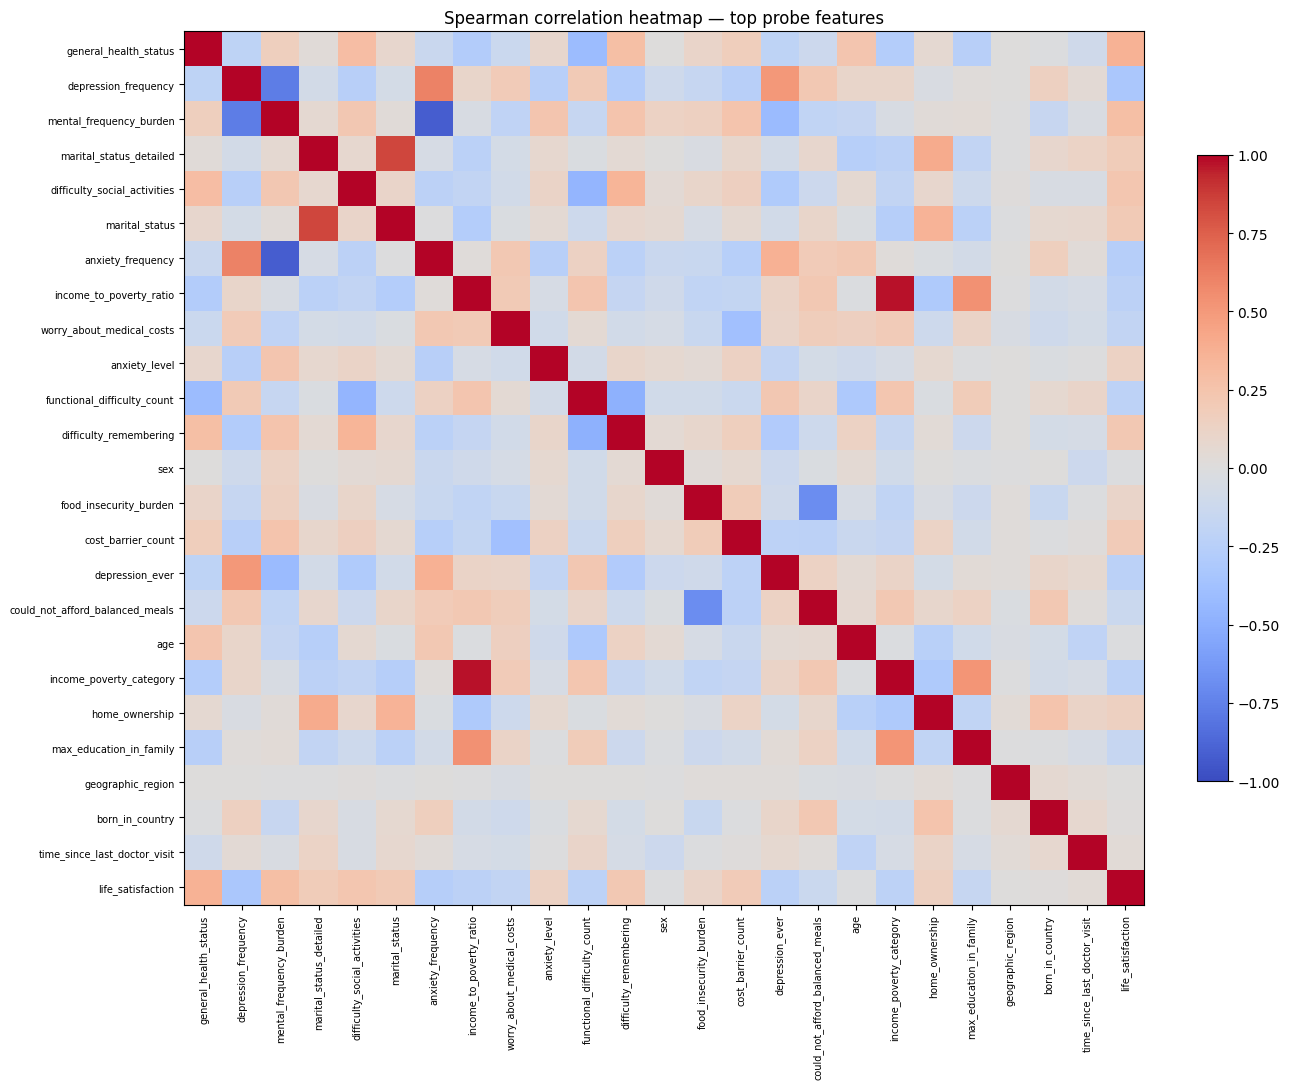

In [13]:
# Correlation matrix on probe-ranked numeric features.
top_corr=[c for c in probe_gain.head(24).index if c in X_num.columns]
corr_df=X_num[top_corr].copy()
corr_df[CFG.TARGET]=y
corr=corr_df.corr(method='spearman')
fig,ax=plt.subplots(figsize=(13,11))
im=ax.imshow(corr.values,aspect='auto',vmin=-1,vmax=1,cmap='coolwarm')
ax.set_xticks(range(len(corr.columns))); ax.set_xticklabels(corr.columns,rotation=90,fontsize=7)
ax.set_yticks(range(len(corr.index))); ax.set_yticklabels(corr.index,fontsize=7)
ax.set_title('Spearman correlation heatmap — top probe features')
plt.colorbar(im,ax=ax,fraction=0.03)
plt.tight_layout(); plt.show()

In [14]:
# Redundancy audit: high absolute Spearman correlations among raw/compact numeric predictors.
red_cols=[c for c in X_num.columns if X_num[c].nunique(dropna=True)>1 and X_num[c].nunique(dropna=True)<500]
red_corr=X_num[red_cols].corr(method='spearman').abs()
pairs=[]
for i in range(len(red_cols)):
    for j in range(i+1,len(red_cols)):
        v=red_corr.iat[i,j]
        if pd.notna(v) and v>=0.94:
            pairs.append((red_cols[i],red_cols[j],float(v)))
redundancy_df=pd.DataFrame(pairs,columns=['feature_a','feature_b','abs_spearman']).sort_values('abs_spearman',ascending=False)
display(redundancy_df.head(40))

,feature_a,feature_b,abs_spearman
5,children_in_family,children_in_household,0.997946
11,ever_used_ecigarette,ecigarette_status,0.996592
9,age,age_band,0.992198
3,health_insurance_type,private_health_insurance,0.982371
8,cancer_ever,cancer_types_count,0.980677
10,smoking_status,ever_smoked,0.978328
0,income_poverty_category,poverty_ratio_band,0.968367
6,adults_in_family,adults_in_household,0.959253
7,has_senior_gov_insurance,senior_government_insurance,0.948933
1,parental_status,children_in_family,0.945703


# 5. Feature Engineering and fold-safe selection

In [15]:
def fold_feature_select(Xtr,ytr,seed,budget=CFG.FINAL_FEATURE_BUDGET):
    idx=np.arange(len(Xtr))
    a,b=train_test_split(idx,test_size=0.18,random_state=seed,stratify=ytr)
    model=lgb.LGBMRegressor(
        objective='regression_l2',n_estimators=CFG.FS_ESTIMATORS,learning_rate=0.04,
        num_leaves=31,min_child_samples=45,colsample_bytree=0.85,reg_lambda=5.0,
        random_state=seed,n_jobs=-1,verbosity=-1
    )
    model.fit(Xtr.iloc[a],ytr[a],eval_set=[(Xtr.iloc[b],ytr[b])],
              callbacks=[lgb.early_stopping(CFG.FS_EARLY_STOPPING,verbose=False)])
    imp=pd.Series(model.booster_.feature_importance(importance_type='gain'),index=Xtr.columns).sort_values(ascending=False)
    selected=list(imp.head(budget).index)
    return selected,imp

# CatBoost raw view: no dictionary-based invalidation. Low-card supplied codes are explicit categoricals.
def prepare_catboost_raw(df):
    base=df.drop(columns=[CFG.TARGET],errors='ignore').copy()
    base=base.drop(columns=[CFG.ID_COL,CFG.HOUSEHOLD_COL]+REDUNDANT_DROP,errors='ignore')
    cat_cols=[]
    for c in base.columns:
        nun=train[c].nunique(dropna=True) if c in train.columns else base[c].nunique(dropna=True)
        if nun <= CFG.CAT_MAX_UNIQUE:
            cat_cols.append(c)
            base[c]=base[c].map(lambda v:'__MISSING__' if pd.isna(v) else str(v))
        else:
            base[c]=pd.to_numeric(base[c],errors='coerce')
            vals=SENTINEL_MAP.get(c,[])
            if vals: base.loc[base[c].isin(vals),c]=np.nan
    return base,cat_cols

X_cat, CAT_COLS = prepare_catboost_raw(train)
X_test_cat,_ = prepare_catboost_raw(test)
print('CatBoost raw view:',X_cat.shape,'categorical:',len(CAT_COLS))

CatBoost raw view: (95609, 173) categorical: 165


### Hyperparameter provenance

V6 does **not** tune model parameters against the leaderboard. The anchor uses one conservative predeclared configuration per tree family with early stopping, while every new V6-specific parameter (`distillation lambda`, `difficulty alpha`, and final blend weight) is selected only from inner train/calibration folds. The large estimator caps therefore act as ceilings rather than fixed effective model sizes. The 140-feature cap is intentionally close to the compact regime that repeatedly concentrated almost all gain importance, while preventing the 400+ engineered-feature expansion that failed in earlier experiments.

# 6. Modeling utilities

In [16]:
def make_lgb_reg(seed):
    return lgb.LGBMRegressor(
        objective='regression_l2',n_estimators=CFG.LGB_N_ESTIMATORS,learning_rate=CFG.LEARNING_RATE,
        num_leaves=31,min_child_samples=42,subsample=0.90,subsample_freq=1,colsample_bytree=0.86,
        reg_alpha=0.03,reg_lambda=5.0,random_state=seed,n_jobs=-1,verbosity=-1
    )

def make_xgb_reg(seed,use_gpu=True):
    p=dict(
        objective='reg:squarederror',eval_metric='rmse',n_estimators=CFG.XGB_N_ESTIMATORS,
        learning_rate=CFG.LEARNING_RATE,max_depth=6,min_child_weight=8,subsample=0.88,
        colsample_bytree=0.86,reg_alpha=0.03,reg_lambda=5.0,tree_method='hist',
        random_state=seed,n_jobs=-1,early_stopping_rounds=CFG.EARLY_STOPPING
    )
    if use_gpu: p['device']='cuda'
    return xgb.XGBRegressor(**p)

def make_cat_reg(seed,use_gpu=True,iterations=None):
    p=dict(
        loss_function='RMSE',eval_metric='RMSE',iterations=iterations or CFG.CAT_ITERATIONS,
        learning_rate=CFG.LEARNING_RATE,depth=7,l2_leaf_reg=7.0,random_strength=0.35,
        random_seed=seed,od_type='Iter',od_wait=CFG.EARLY_STOPPING,allow_writing_files=False,
        verbose=CFG.VERBOSE
    )
    if use_gpu: p.update(task_type='GPU',devices=CFG.CAT_DEVICES)
    else: p.update(task_type='CPU',thread_count=-1)
    return CatBoostRegressor(**p)

def fit_lgb_reg(Xtr,ytr,Xv,yv,Xt,seed,sample_weight=None):
    m=make_lgb_reg(seed)
    m.fit(Xtr,ytr,sample_weight=sample_weight,eval_set=[(Xv,yv)],callbacks=[lgb.early_stopping(CFG.EARLY_STOPPING,verbose=False)])
    return m,m.predict(Xv,num_iteration=m.best_iteration_),m.predict(Xt,num_iteration=m.best_iteration_)

def fit_xgb_reg(Xtr,ytr,Xv,yv,Xt,seed,sample_weight=None):
    last=None
    for gpu in ([True,False] if CFG.USE_GPU else [False]):
        m=make_xgb_reg(seed,gpu)
        try:
            m.fit(Xtr,ytr,sample_weight=sample_weight,eval_set=[(Xv,yv)],verbose=False)
            return m,m.predict(Xv),m.predict(Xt)
        except Exception as e:
            last=e
            if gpu:
                print('XGB GPU fallback:',repr(e)); gc.collect(); continue
            raise

def fit_cat_reg(Xtr,ytr,Xv,yv,Xt,cat_cols,seed,sample_weight=None,iterations=None):
    last=None
    for gpu in ([True,False] if CFG.USE_GPU else [False]):
        m=make_cat_reg(seed,gpu,iterations=iterations)
        try:
            m.fit(Xtr,ytr,sample_weight=sample_weight,eval_set=(Xv,yv),cat_features=cat_cols,use_best_model=True)
            return m,m.predict(Xv),m.predict(Xt)
        except Exception as e:
            last=e
            if gpu:
                print('CatBoost GPU fallback:',repr(e)); gc.collect(); continue
            raise

In [17]:
# LightGBM binary helper for CORN conditional tasks.
def make_lgb_bin(seed):
    return lgb.LGBMClassifier(
        objective='binary',n_estimators=3200,learning_rate=0.03,num_leaves=31,min_child_samples=35,
        subsample=0.90,subsample_freq=1,colsample_bytree=0.86,reg_lambda=5.0,
        random_state=seed,n_jobs=-1,verbosity=-1
    )

def fit_corn_lgb(Xtr,ytr,Xv,Xt,seed,groups_tr=None):
    # q1=P(y>1), q2=P(y>2 | y>1), q3=P(y>3 | y>2)
    probs_v=[]; probs_t=[]
    if groups_tr is None: groups_tr=np.arange(len(ytr)).astype(str)
    groups_tr=np.asarray(groups_tr)
    tasks=[
        (np.ones(len(ytr),dtype=bool),(ytr>1).astype(int)),
        (ytr>1,(ytr>2).astype(int)),
        (ytr>2,(ytr>3).astype(int)),
    ]
    for j,(mask,target) in enumerate(tasks):
        Xj=Xtr.iloc[mask]; yj=target[mask]; gj=groups_tr[mask]
        split=StratifiedGroupKFold(n_splits=4,shuffle=True,random_state=seed+17*j)
        a,b=next(split.split(Xj,yj,groups=gj))
        m=make_lgb_bin(seed+17*j)
        m.fit(Xj.iloc[a],yj[a],eval_set=[(Xj.iloc[b],yj[b])],callbacks=[lgb.early_stopping(120,verbose=False)])
        probs_v.append(m.predict_proba(Xv,num_iteration=m.best_iteration_)[:,1])
        probs_t.append(m.predict_proba(Xt,num_iteration=m.best_iteration_)[:,1])
        del m; gc.collect()
    p1v=probs_v[0]; p2v=p1v*probs_v[1]; p3v=p2v*probs_v[2]
    p1t=probs_t[0]; p2t=p1t*probs_t[1]; p3t=p2t*probs_t[2]
    return 1.0+p1v+p2v+p3v, 1.0+p1t+p2t+p3t

In [18]:
def inner_teacher_oof(X,y_local,groups_local,seed):
    """Strict inner OOF teacher predictions for distillation / difficulty weights."""
    splitter=StratifiedGroupKFold(n_splits=CFG.INNER_FOLDS,shuffle=True,random_state=seed)
    out=np.zeros(len(X),dtype=float)
    for k,(a,b) in enumerate(splitter.split(X,y_local,groups=groups_local)):
        m=make_lgb_reg(seed+101*k)
        m.fit(X.iloc[a],y_local[a],eval_set=[(X.iloc[b],y_local[b])],callbacks=[lgb.early_stopping(120,verbose=False)])
        out[b]=m.predict(X.iloc[b],num_iteration=m.best_iteration_)
        del m; gc.collect()
    return out

def difficulty_weights(y_true,teacher_pred,alpha,max_weight=CFG.DIFFICULTY_MAX_WEIGHT):
    y_true=np.asarray(y_true,float); teacher_pred=np.asarray(teacher_pred,float)
    err=np.abs(y_true-teacher_pred)
    # Robust normalization from train-only inner OOF errors.
    scale=np.quantile(err,0.90)
    diff=np.clip(err/(scale+1e-8),0,1)
    adjacent=np.isin(y_true,[1,2]).astype(float)
    # Focus on repeatedly hard adjacent rows without duplicating any observations.
    w=1.0+alpha*diff*(0.65+0.35*adjacent)
    return np.clip(w,1.0,max_weight)

# 6A. Multi-probe candidate gate

In [19]:
def inner_fit_cal_split(indices,seed):
    idx=np.asarray(indices)
    yloc=y[idx]; gloc=groups[idx]
    split=StratifiedGroupKFold(n_splits=5,shuffle=True,random_state=seed)
    fit_rel,cal_rel=next(split.split(np.zeros(len(idx)),yloc,groups=gloc))
    return idx[fit_rel],idx[cal_rel]

def calibrate_blend(ycal,base_cal,cand_cal):
    best=None
    for a in CFG.BLEND_ALPHA_GRID:
        p=(1-a)*np.asarray(base_cal)+a*np.asarray(cand_cal)
        thr,score=optimize_thresholds(ycal,p,maxiter=180)
        if best is None or score>best['qwk']:
            best={'alpha':float(a),'thresholds':thr,'qwk':float(score)}
    return best

def probe_anchor(fit_idx,cal_idx,val_idx,selected,seed):
    # Two-model compact anchor for cheap candidate screening.
    Xfit=X_num.iloc[fit_idx][selected]; Xcal=X_num.iloc[cal_idx][selected]; Xval=X_num.iloc[val_idx][selected]
    ml,pcal_l,pval_l=fit_lgb_reg(Xfit,y[fit_idx],Xcal,y[cal_idx],Xval,seed+1)
    del ml; gc.collect()

    Cfit=X_cat.iloc[fit_idx]; Ccal=X_cat.iloc[cal_idx]; Cval=X_cat.iloc[val_idx]
    mc,pcal_c,pval_c=fit_cat_reg(Cfit,y[fit_idx],Ccal,y[cal_idx],Cval,CAT_COLS,seed+2,iterations=2600)
    del mc; gc.collect()
    return (pcal_l+pcal_c)/2, (pval_l+pval_c)/2

In [20]:
def probe_distilled(fit_idx,cal_idx,val_idx,selected,seed):
    # Teacher uses compact numeric view; student uses raw-categorical CatBoost.
    Xfit=X_num.iloc[fit_idx][selected]
    teacher=inner_teacher_oof(Xfit,y[fit_idx],groups[fit_idx],seed+300)
    Cfit=X_cat.iloc[fit_idx]; Ccal=X_cat.iloc[cal_idx]
    best=None
    for lam in CFG.DISTILL_LAMBDA_GRID:
        target=lam*y[fit_idx]+(1-lam)*teacher
        m,pcal,_=fit_cat_reg(Cfit,target,Ccal,y[cal_idx],Ccal,CAT_COLS,seed+int(lam*1000),iterations=2400)
        score=rmse(y[cal_idx],pcal)
        if best is None or score<best['rmse']:
            best={'lambda':float(lam),'rmse':score}
        del m; gc.collect()
    lam=best['lambda']

    outer_idx=np.concatenate([fit_idx,cal_idx])
    Xouter=X_num.iloc[outer_idx][selected]
    teacher_outer=inner_teacher_oof(Xouter,y[outer_idx],groups[outer_idx],seed+700)
    target_outer=lam*y[outer_idx]+(1-lam)*teacher_outer
    m,pval,_=fit_cat_reg(X_cat.iloc[outer_idx],target_outer,X_cat.iloc[val_idx],y[val_idx],X_cat.iloc[val_idx],CAT_COLS,seed+702,iterations=3000)
    del m; gc.collect()

    target_fit=lam*y[fit_idx]+(1-lam)*teacher
    mcal,pcal,_=fit_cat_reg(Cfit,target_fit,Ccal,y[cal_idx],Ccal,CAT_COLS,seed+703,iterations=2400)
    del mcal; gc.collect()
    return pcal,pval,{'lambda':lam}

def probe_weighted(fit_idx,cal_idx,val_idx,selected,seed):
    Xfit=X_num.iloc[fit_idx][selected]
    teacher=inner_teacher_oof(Xfit,y[fit_idx],groups[fit_idx],seed+400)
    Cfit=X_cat.iloc[fit_idx]; Ccal=X_cat.iloc[cal_idx]
    best=None
    for alpha in CFG.DIFFICULTY_ALPHA_GRID:
        w=difficulty_weights(y[fit_idx],teacher,alpha)
        m,pcal,_=fit_cat_reg(Cfit,y[fit_idx],Ccal,y[cal_idx],Ccal,CAT_COLS,seed+int(alpha*1000),sample_weight=w,iterations=2400)
        score=rmse(y[cal_idx],pcal)
        if best is None or score<best['rmse']:
            best={'alpha':float(alpha),'rmse':score}
        del m; gc.collect()
    alpha=best['alpha']

    outer_idx=np.concatenate([fit_idx,cal_idx])
    Xouter=X_num.iloc[outer_idx][selected]
    teacher_outer=inner_teacher_oof(Xouter,y[outer_idx],groups[outer_idx],seed+800)
    wouter=difficulty_weights(y[outer_idx],teacher_outer,alpha)
    m,pval,_=fit_cat_reg(X_cat.iloc[outer_idx],y[outer_idx],X_cat.iloc[val_idx],y[val_idx],X_cat.iloc[val_idx],CAT_COLS,seed+802,sample_weight=wouter,iterations=3000)
    del m; gc.collect()

    wfit=difficulty_weights(y[fit_idx],teacher,alpha)
    mcal,pcal,_=fit_cat_reg(Cfit,y[fit_idx],Ccal,y[cal_idx],Ccal,CAT_COLS,seed+803,sample_weight=wfit,iterations=2400)
    del mcal; gc.collect()
    return pcal,pval,{'alpha':alpha}

def probe_corn(fit_idx,cal_idx,val_idx,selected,seed):
    pcal,_=fit_corn_lgb(X_num.iloc[fit_idx][selected],y[fit_idx],X_num.iloc[cal_idx][selected],X_num.iloc[cal_idx][selected],seed+500,groups[fit_idx])
    outer_idx=np.concatenate([fit_idx,cal_idx])
    pval,_=fit_corn_lgb(X_num.iloc[outer_idx][selected],y[outer_idx],X_num.iloc[val_idx][selected],X_num.iloc[val_idx][selected],seed+900,groups[outer_idx])
    return pcal,pval,{}

In [21]:
probe_rows=[]
probe_choice_details=[]
CANDIDATES=['distilled','difficulty_weighted','corn']

for f in CFG.PROBE_FOLDS:
    tr_idx,va_idx=folds[f]
    fit_idx,cal_idx=inner_fit_cal_split(tr_idx,CFG.SEED+1000+f)
    selected,_=fold_feature_select(X_num.iloc[fit_idx],y[fit_idx],CFG.SEED+1100+f)
    base_cal,base_val=probe_anchor(fit_idx,cal_idx,va_idx,selected,CFG.SEED+1200+f)
    base_thr,_=optimize_thresholds(y[cal_idx],base_cal,maxiter=180)
    base_q=qwk(y[va_idx],apply_thresholds(base_val,base_thr))
    base_auc=boundary_auc(y[va_idx],base_val)
    print('\nPROBE FOLD',f,'base_qwk',base_q,'auc12',base_auc['auc_1_vs_2'])

    for name in CANDIDATES:
        if name=='distilled': ccal,cval,detail=probe_distilled(fit_idx,cal_idx,va_idx,selected,CFG.SEED+2000+f)
        elif name=='difficulty_weighted': ccal,cval,detail=probe_weighted(fit_idx,cal_idx,va_idx,selected,CFG.SEED+3000+f)
        else: ccal,cval,detail=probe_corn(fit_idx,cal_idx,va_idx,selected,CFG.SEED+4000+f)

        blend=calibrate_blend(y[cal_idx],base_cal,ccal)
        pval=(1-blend['alpha'])*base_val+blend['alpha']*cval
        cq=qwk(y[va_idx],apply_thresholds(pval,blend['thresholds']))
        auc=boundary_auc(y[va_idx],pval)
        row={
            'fold':f,'candidate':name,'base_qwk':base_q,'candidate_blend_qwk':cq,'gain':cq-base_q,
            'blend_alpha':blend['alpha'],'base_auc12':base_auc['auc_1_vs_2'],'candidate_auc12':auc['auc_1_vs_2'],
            'auc12_gain':auc['auc_1_vs_2']-base_auc['auc_1_vs_2'],
            **{f'param_{k}':v for k,v in detail.items()}
        }
        probe_rows.append(row)
        probe_choice_details.append({'fold':f,'candidate':name,'detail':detail,'blend':blend})
        print(name,row)

probe_df=pd.DataFrame(probe_rows)
display(probe_df)

0:	learn: 0.6060283	test: 0.5996852	best: 0.5996852 (0)	total: 177ms	remaining: 7m 39s
500:	learn: 0.5100432	test: 0.5148390	best: 0.5148346 (496)	total: 37.4s	remaining: 2m 36s
1000:	learn: 0.5041804	test: 0.5141037	best: 0.5141022 (998)	total: 1m 15s	remaining: 2m
1500:	learn: 0.4989920	test: 0.5137268	best: 0.5137204 (1494)	total: 1m 53s	remaining: 1m 23s
2000:	learn: 0.4937285	test: 0.5134345	best: 0.5134345 (2000)	total: 2m 34s	remaining: 46.3s
2500:	learn: 0.4885112	test: 0.5133613	best: 0.5133046 (2324)	total: 3m 16s	remaining: 7.79s
bestTest = 0.513304603
bestIteration = 2324
Shrink model to first 2325 iterations.

PROBE FOLD 0 base_qwk 0.47817414720171403 auc12 0.7651758433547363
0:	learn: 0.4225287	test: 0.5996823	best: 0.5996823 (0)	total: 87.3ms	remaining: 3m 29s
500:	learn: 0.2815386	test: 0.5147792	best: 0.5147791 (499)	total: 38.5s	remaining: 2m 25s
1000:	learn: 0.2772999	test: 0.5140872	best: 0.5140872 (1000)	total: 1m 17s	remaining: 1m 48s
1500:	learn: 0.2736881	test: 

,fold,candidate,base_qwk,candidate_blend_qwk,gain,blend_alpha,base_auc12,candidate_auc12,auc12_gain,param_lambda,param_alpha
0,0,distilled,0.478174,0.478207,0.000033,0.10,0.765176,0.765314,0.000138,0.55,NaN
1,0,difficulty_weighted,0.478174,0.477244,-0.000930,0.10,0.765176,0.765280,0.000104,NaN,0.35
2,0,corn,0.478174,0.478174,0.000000,0.00,0.765176,0.765176,0.000000,NaN,NaN
3,2,distilled,0.486711,0.485188,-0.001524,0.30,0.768831,0.769280,0.000450,0.82,NaN
4,2,difficulty_weighted,0.486711,0.488410,0.001699,0.30,0.768831,0.769193,0.000362,NaN,0.35
5,2,corn,0.486711,0.489477,0.002766,0.20,0.768831,0.769414,0.000584,NaN,NaN
6,3,distilled,0.469518,0.467029,-0.002489,0.85,0.758778,0.759329,0.000551,0.70,NaN
7,3,difficulty_weighted,0.469518,0.464074,-0.005444,0.40,0.758778,0.759285,0.000507,NaN,0.35
8,3,corn,0.469518,0.467070,-0.002448,0.20,0.758778,0.759192,0.000414,NaN,NaN


In [22]:
probe_summary=(probe_df.groupby('candidate')
               .agg(mean_gain=('gain','mean'),wins=('gain',lambda s:int((s>0).sum())),
                    mean_qwk=('candidate_blend_qwk','mean'),mean_auc12_gain=('auc12_gain','mean'))
               .sort_values(['mean_gain','wins'],ascending=False))
probe_summary['promote']=(probe_summary.mean_gain>=CFG.PROMOTE_MIN_MEAN_GAIN)&(probe_summary.wins>=CFG.PROMOTE_MIN_WINS)
display(probe_summary)

BEST_CANDIDATE=str(probe_summary.index[0])
BEST_PROBE_GAIN=float(probe_summary.iloc[0].mean_gain)
PROMOTED=bool(probe_summary.iloc[0].promote)
RUN_DIAGNOSTIC_FULLCV=bool(PROMOTED or (BEST_PROBE_GAIN>=CFG.DIAGNOSTIC_FULLCV_MIN_GAIN and int(probe_summary.iloc[0].wins)>=2))
print('BEST_CANDIDATE:',BEST_CANDIDATE,'PROMOTED:',PROMOTED,'RUN_DIAGNOSTIC_FULLCV:',RUN_DIAGNOSTIC_FULLCV)

,mean_gain,wins,mean_qwk,mean_auc12_gain,promote
candidate,,,,,
corn,0.000106,1,0.478241,0.000332,False
distilled,-0.001327,1,0.476808,0.000380,False
difficulty_weighted,-0.001559,1,0.476576,0.000325,False


BEST_CANDIDATE: corn PROMOTED: False RUN_DIAGNOSTIC_FULLCV: False


# 6B. Full 5-fold V2-lite anchor

In [23]:
anchor_names=['lgb','xgb','cat']
oof_anchor={m:np.zeros(len(train),float) for m in anchor_names}
test_anchor={m:np.zeros(len(test),float) for m in anchor_names}
anchor_fold_metrics=[]
feature_rows=[]
selected_by_fold={}

for f,(tr_idx,va_idx) in enumerate(folds):
    print('\n'+'='*84+'\nANCHOR FOLD',f,'\n'+'='*84)
    selected,imp=fold_feature_select(X_num.iloc[tr_idx],y[tr_idx],CFG.SEED+5000+f)
    selected_by_fold[f]=selected
    Xtr=X_num.iloc[tr_idx][selected]; Xv=X_num.iloc[va_idx][selected]; Xt=X_test_num[selected]

    m,pv,pt=fit_lgb_reg(Xtr,y[tr_idx],Xv,y[va_idx],Xt,CFG.SEED+5100+f)
    oof_anchor['lgb'][va_idx]=pv; test_anchor['lgb']+=pt/CFG.N_FOLDS
    for feat,val in zip(selected,m.booster_.feature_importance(importance_type='gain')):
        feature_rows.append({'fold':f,'model':'lgb','feature':feat,'importance':float(val)})
    del m; gc.collect()

    m,pv,pt=fit_xgb_reg(Xtr,y[tr_idx],Xv,y[va_idx],Xt,CFG.SEED+5200+f)
    oof_anchor['xgb'][va_idx]=pv; test_anchor['xgb']+=pt/CFG.N_FOLDS
    for feat,val in zip(selected,m.feature_importances_): feature_rows.append({'fold':f,'model':'xgb','feature':feat,'importance':float(val)})
    del m; gc.collect()

    Ctr=X_cat.iloc[tr_idx]; Cv=X_cat.iloc[va_idx]; Ct=X_test_cat
    m,pv,pt=fit_cat_reg(Ctr,y[tr_idx],Cv,y[va_idx],Ct,CAT_COLS,CFG.SEED+5300+f)
    oof_anchor['cat'][va_idx]=pv; test_anchor['cat']+=pt/CFG.N_FOLDS
    try:
        for feat,val in zip(Ctr.columns,m.get_feature_importance()): feature_rows.append({'fold':f,'model':'cat','feature':feat,'importance':float(val)})
    except Exception: pass
    del m; gc.collect()

    for name in anchor_names:
        t,qq=optimize_thresholds(y[va_idx],oof_anchor[name][va_idx],maxiter=160)
        anchor_fold_metrics.append({'fold':f,'model':name,'diagnostic_qwk':qq,'rmse':rmse(y[va_idx],oof_anchor[name][va_idx]),**boundary_auc(y[va_idx],oof_anchor[name][va_idx])})

anchor_fold_metrics=pd.DataFrame(anchor_fold_metrics)
display(anchor_fold_metrics)


ANCHOR FOLD 0 
0:	learn: 0.6047181	test: 0.6017867	best: 0.6017867 (0)	total: 96.7ms	remaining: 6m 45s
500:	learn: 0.5096581	test: 0.5165670	best: 0.5165670 (500)	total: 39.1s	remaining: 4m 49s
1000:	learn: 0.5041084	test: 0.5159393	best: 0.5159357 (997)	total: 1m 19s	remaining: 4m 12s
1500:	learn: 0.4992254	test: 0.5156290	best: 0.5156179 (1490)	total: 1m 59s	remaining: 3m 34s
2000:	learn: 0.4948772	test: 0.5154666	best: 0.5154656 (1997)	total: 2m 40s	remaining: 2m 55s
bestTest = 0.5153647528
bestIteration = 2260
Shrink model to first 2261 iterations.

ANCHOR FOLD 1 
0:	learn: 0.6044536	test: 0.6034316	best: 0.6034316 (0)	total: 92.9ms	remaining: 6m 29s
500:	learn: 0.5106468	test: 0.5154005	best: 0.5154005 (500)	total: 38.3s	remaining: 4m 42s
1000:	learn: 0.5055330	test: 0.5145809	best: 0.5145809 (1000)	total: 1m 16s	remaining: 4m 5s
1500:	learn: 0.5009502	test: 0.5141152	best: 0.5141118 (1498)	total: 1m 56s	remaining: 3m 28s
2000:	learn: 0.4963489	test: 0.5138423	best: 0.5138423 (20

,fold,model,diagnostic_qwk,rmse,auc_gt1,auc_gt2,auc_gt3,auc_1_vs_2
0,0,lgb,0.481497,0.514870,0.778854,0.869898,0.804864,0.765114
1,0,xgb,0.483188,0.515414,0.778760,0.869691,0.802587,0.765046
2,0,cat,0.478723,0.515365,0.778984,0.868682,0.802968,0.765292
3,1,lgb,0.485725,0.514213,0.781004,0.868595,0.835121,0.767364
4,1,xgb,0.483352,0.514598,0.780923,0.868600,0.833825,0.767241
5,1,cat,0.486522,0.513681,0.781871,0.869075,0.834324,0.768248
6,2,lgb,0.488020,0.514438,0.782669,0.874650,0.816762,0.767984
7,2,xgb,0.487616,0.514873,0.782522,0.874638,0.817733,0.767792
8,2,cat,0.492042,0.513501,0.783961,0.875892,0.820254,0.769272
9,3,lgb,0.471039,0.519843,0.772550,0.867764,0.787405,0.758541


In [24]:
ANCHOR_OOF_MAT=np.column_stack([oof_anchor[m] for m in anchor_names])
ANCHOR_TEST_MAT=np.column_stack([test_anchor[m] for m in anchor_names])

# Small simplex, cross-fitted. Weight choice for each validation fold uses only the other folds.
weight_grid=[]
for a in np.arange(0.1,0.81,0.1):
    for b in np.arange(0.1,0.91-a,0.1):
        c=1-a-b
        if c>=0.099: weight_grid.append(np.array([a,b,c]))
weight_grid.append(np.array([1/3,1/3,1/3]))

anchor_cross_score=np.zeros(len(train),float)
anchor_cross_class=np.zeros(len(train),int)
anchor_cal_rows=[]
for f in range(CFG.N_FOLDS):
    cal=fold_id!=f; val=fold_id==f
    best=None
    for w in weight_grid:
        pc=ANCHOR_OOF_MAT[cal]@w
        thr,qq=optimize_thresholds(y[cal],pc,maxiter=140)
        if best is None or qq>best['qwk']: best={'w':w,'thr':thr,'qwk':qq}
    anchor_cross_score[val]=ANCHOR_OOF_MAT[val]@best['w']
    anchor_cross_class[val]=apply_thresholds(anchor_cross_score[val],best['thr'])
    anchor_cal_rows.append({'fold':f,'weights':best['w'].tolist(),'thresholds':best['thr'].tolist(),'cal_qwk':best['qwk'],'val_qwk':qwk(y[val],anchor_cross_class[val])})
ANCHOR_CROSSFIT_QWK=qwk(y,anchor_cross_class)
print('ANCHOR CROSSFIT QWK:',ANCHOR_CROSSFIT_QWK)
print('Anchor boundary AUC:',boundary_auc(y,anchor_cross_score))
display(pd.DataFrame(anchor_cal_rows))

ANCHOR CROSSFIT QWK: 0.47915839158259343
Anchor boundary AUC: {'auc_gt1': 0.7786817423412357, 'auc_gt2': 0.8724345069934093, 'auc_gt3': 0.8084302778289711, 'auc_1_vs_2': 0.7643703072753714}


,fold,weights,thresholds,cal_qwk,val_qwk
0,0,"[0.1, 0.4, 0.5]","[1.5414472946029478, 2.019970322661222, 2.4923...",0.481636,0.475479
1,1,"[0.4, 0.2, 0.39999999999999997]","[1.5612585438021789, 2.0225597970360836, 2.490...",0.480382,0.484944
2,2,"[0.4, 0.2, 0.39999999999999997]","[1.5618515081296416, 2.0226982912436853, 2.517...",0.479266,0.487825
3,3,"[0.30000000000000004, 0.1, 0.6]","[1.5549361333141498, 2.0212748527815654, 2.484...",0.483532,0.471225
4,4,"[0.4, 0.1, 0.5]","[1.560398922769254, 2.0239399768256785, 2.5083...",0.482335,0.476409


# 4B. Error-cohort EDA — adjacent 1↔2 mistakes

In [25]:
# Cohorts are derived entirely from OOF predictions, never in-sample fits.
mask12=np.isin(y,[1,2])
pred12=anchor_cross_class
cohort=np.full(len(train),'other',object)
cohort[(y==1)&(pred12==1)]='true1_pred1'
cohort[(y==1)&(pred12==2)]='true1_pred2'
cohort[(y==2)&(pred12==1)]='true2_pred1'
cohort[(y==2)&(pred12==2)]='true2_pred2'
print(pd.Series(cohort[mask12]).value_counts())

# Compare top probe features across the four major adjacent cohorts.
cohort_features=[c for c in probe_gain.head(25).index if c in X_num.columns]
cohort_means=X_num.loc[mask12,cohort_features].assign(cohort=cohort[mask12]).groupby('cohort').mean(numeric_only=True).T
cohort_means['spread']=cohort_means.max(axis=1)-cohort_means.min(axis=1)
display(cohort_means.sort_values('spread',ascending=False).head(25))

true1_pred1    30641
true2_pred2    26879
true2_pred1    15456
true1_pred2    11560
other           6621
Name: count, dtype: int64


cohort,other,true1_pred1,true1_pred2,true2_pred1,true2_pred2,spread
income_poverty_category,7.569788,12.119969,9.633602,11.579750,9.359302,4.550180
mental_frequency_burden,7.235463,2.806828,4.033823,3.012875,4.341382,4.428636
functional_difficulty_count,5.931128,9.628472,8.531747,9.488742,8.426913,3.697343
income_to_poverty_ratio,2.440000,5.447768,3.457445,4.857681,3.327588,3.007768
depression_frequency,2.410743,4.821559,4.240106,4.746163,4.084125,2.410816
marital_status_detailed,5.211715,2.866759,4.503812,3.196161,4.746951,2.344956
anxiety_frequency,1.961016,4.172660,3.446832,4.024695,3.280549,2.211644
general_health_status,3.719307,1.722685,2.788456,1.936616,2.886249,1.996621
max_education_in_family,5.457484,7.242013,6.064470,6.930834,6.000566,1.784530
cost_barrier_count,1.479535,0.114259,0.469896,0.159226,0.552736,1.365276


In [26]:
# Error separability diagnostic: if raw features can easily classify correct-vs-wrong adjacent rows,
# there is still a local correction opportunity; otherwise extra feature engineering is unlikely to help.
err_mask=mask12 & np.isin(anchor_cross_class,[1,2])
err_target=(anchor_cross_class[err_mask]!=y[err_mask]).astype(int)
err_X=X_num.loc[err_mask,cohort_features]
idx=np.arange(len(err_X))
a,b=train_test_split(idx,test_size=0.25,random_state=CFG.SEED,stratify=err_target)
err_model=lgb.LGBMClassifier(n_estimators=1200,learning_rate=0.035,num_leaves=25,min_child_samples=45,reg_lambda=5,random_state=CFG.SEED,n_jobs=-1,verbosity=-1)
err_model.fit(err_X.iloc[a],err_target[a],eval_set=[(err_X.iloc[b],err_target[b])],callbacks=[lgb.early_stopping(100,verbose=False)])
err_auc=float(roc_auc_score(err_target[b],err_model.predict_proba(err_X.iloc[b],num_iteration=err_model.best_iteration_)[:,1]))
print('Adjacent-error separability AUC:',err_auc)

Adjacent-error separability AUC: 0.6234167163290244


# 6C. Full CV for the best new candidate

In [27]:
def tune_candidate_inner(candidate,tr_idx,selected,seed):
    fit_idx,cal_idx=inner_fit_cal_split(tr_idx,seed)
    Xfit=X_num.iloc[fit_idx][selected]
    teacher=inner_teacher_oof(Xfit,y[fit_idx],groups[fit_idx],seed+100)
    Cfit=X_cat.iloc[fit_idx]; Ccal=X_cat.iloc[cal_idx]

    if candidate=='distilled':
        best=None
        for lam in CFG.DISTILL_LAMBDA_GRID:
            target=lam*y[fit_idx]+(1-lam)*teacher
            m,pcal,_=fit_cat_reg(Cfit,target,Ccal,y[cal_idx],Ccal,CAT_COLS,seed+int(lam*1000),iterations=2600)
            r=rmse(y[cal_idx],pcal)
            if best is None or r<best['rmse']: best={'lambda':float(lam),'rmse':r}
            del m; gc.collect()
        return best
    if candidate=='difficulty_weighted':
        best=None
        for alpha in CFG.DIFFICULTY_ALPHA_GRID:
            w=difficulty_weights(y[fit_idx],teacher,alpha)
            m,pcal,_=fit_cat_reg(Cfit,y[fit_idx],Ccal,y[cal_idx],Ccal,CAT_COLS,seed+int(alpha*1000),sample_weight=w,iterations=2600)
            r=rmse(y[cal_idx],pcal)
            if best is None or r<best['rmse']: best={'alpha':float(alpha),'rmse':r}
            del m; gc.collect()
        return best
    return {}

def fit_candidate_full_fold(candidate,tr_idx,va_idx,selected,seed):
    Xtr=X_num.iloc[tr_idx][selected]; Xv=X_num.iloc[va_idx][selected]; Xt=X_test_num[selected]
    if candidate=='corn':
        pv,pt=fit_corn_lgb(Xtr,y[tr_idx],Xv,Xt,seed,groups[tr_idx])
        return pv,pt,{}

    choice=tune_candidate_inner(candidate,tr_idx,selected,seed+50)
    teacher=inner_teacher_oof(Xtr,y[tr_idx],groups[tr_idx],seed+200)
    if candidate=='distilled':
        lam=choice['lambda']; target=lam*y[tr_idx]+(1-lam)*teacher
        m,pv,pt=fit_cat_reg(X_cat.iloc[tr_idx],target,X_cat.iloc[va_idx],y[va_idx],X_test_cat,CAT_COLS,seed+300,iterations=3600)
    else:
        alpha=choice['alpha']; w=difficulty_weights(y[tr_idx],teacher,alpha)
        m,pv,pt=fit_cat_reg(X_cat.iloc[tr_idx],y[tr_idx],X_cat.iloc[va_idx],y[va_idx],X_test_cat,CAT_COLS,seed+300,sample_weight=w,iterations=3600)
    del m; gc.collect()
    return pv,pt,choice

In [28]:
CANDIDATE_OOF=None
CANDIDATE_TEST=None
candidate_fold_rows=[]

if RUN_DIAGNOSTIC_FULLCV:
    CANDIDATE_OOF=np.zeros(len(train),float)
    CANDIDATE_TEST=np.zeros(len(test),float)
    for f,(tr_idx,va_idx) in enumerate(folds):
        print('\nFULL CANDIDATE',BEST_CANDIDATE,'FOLD',f)
        selected=selected_by_fold[f]
        pv,pt,choice=fit_candidate_full_fold(BEST_CANDIDATE,tr_idx,va_idx,selected,CFG.SEED+7000+f)
        CANDIDATE_OOF[va_idx]=pv; CANDIDATE_TEST+=pt/CFG.N_FOLDS
        thr,qq=optimize_thresholds(y[va_idx],pv,maxiter=160)
        candidate_fold_rows.append({'fold':f,'candidate':BEST_CANDIDATE,'diagnostic_qwk':qq,'rmse':rmse(y[va_idx],pv),**boundary_auc(y[va_idx],pv),**choice})
    display(pd.DataFrame(candidate_fold_rows))
else:
    print('No candidate cleared the multi-probe diagnostic gate. Full candidate CV skipped.')

No candidate cleared the multi-probe diagnostic gate. Full candidate CV skipped.


# 7. Evaluation and final cross-fitted blend

In [29]:
# Candidate architecture is selected from train-only probes. Final blend weights/thresholds are cross-fitted across outer folds.
if CANDIDATE_OOF is not None:
    final_cross_score=np.zeros(len(train),float)
    final_cross_class=np.zeros(len(train),int)
    final_blend_rows=[]
    for f in range(CFG.N_FOLDS):
        cal=fold_id!=f; val=fold_id==f
        best=None
        for a in CFG.BLEND_ALPHA_GRID:
            pc=(1-a)*anchor_cross_score[cal]+a*CANDIDATE_OOF[cal]
            thr,qq=optimize_thresholds(y[cal],pc,maxiter=160)
            if best is None or qq>best['qwk']: best={'alpha':float(a),'thr':thr,'qwk':qq}
        final_cross_score[val]=(1-best['alpha'])*anchor_cross_score[val]+best['alpha']*CANDIDATE_OOF[val]
        final_cross_class[val]=apply_thresholds(final_cross_score[val],best['thr'])
        final_blend_rows.append({'fold':f,'alpha':best['alpha'],'thresholds':best['thr'].tolist(),'cal_qwk':best['qwk'],'val_qwk':qwk(y[val],final_cross_class[val])})
    FINAL_CROSSFIT_QWK=qwk(y,final_cross_class)
else:
    final_cross_score=anchor_cross_score.copy(); final_cross_class=anchor_cross_class.copy()
    FINAL_CROSSFIT_QWK=ANCHOR_CROSSFIT_QWK
    final_blend_rows=[]

print('ANCHOR CROSSFIT QWK:',ANCHOR_CROSSFIT_QWK)
print('FINAL  CROSSFIT QWK:',FINAL_CROSSFIT_QWK,'gain',FINAL_CROSSFIT_QWK-ANCHOR_CROSSFIT_QWK)
print('FINAL boundary AUC:',boundary_auc(y,final_cross_score))
print('FINAL RMSE:',rmse(y,final_cross_score))
if final_blend_rows: display(pd.DataFrame(final_blend_rows))

ANCHOR CROSSFIT QWK: 0.47915839158259343
FINAL  CROSSFIT QWK: 0.47915839158259343 gain 0.0
FINAL boundary AUC: {'auc_gt1': 0.7786817423412357, 'auc_gt2': 0.8724345069934093, 'auc_gt3': 0.8084302778289711, 'auc_1_vs_2': 0.7643703072753714}
FINAL RMSE: 0.5160406899787494


In [30]:
# Unique-respondent diagnostic mirrors the known duplicated-ID structure.
oof_uid=pd.DataFrame({'id':train[CFG.ID_COL].to_numpy(),'y':y,'score':final_cross_score}).groupby('id',as_index=False).agg(y=('y','first'),score=('score','mean'))
uid_thr,UID_DIAGNOSTIC_QWK=optimize_thresholds(oof_uid.y.to_numpy(),oof_uid.score.to_numpy(),maxiter=260)
print('Unique-ID diagnostic QWK:',UID_DIAGNOSTIC_QWK,'rows',len(oof_uid))

cm=pd.DataFrame(confusion_matrix(y,final_cross_class,labels=[1,2,3,4]),index=[1,2,3,4],columns=[1,2,3,4])
display(cm)

Unique-ID diagnostic QWK: 0.48009703355394806 rows 94663


,1,2,3,4
1,30641,11560,707,60
2,15456,26879,5315,539
3,162,1270,1592,535
4,140,198,293,262


In [31]:
# Prediction diversity diagnostic.
pred_frames={m:oof_anchor[m] for m in anchor_names}
if CANDIDATE_OOF is not None: pred_frames[BEST_CANDIDATE]=CANDIDATE_OOF
pred_corr=pd.DataFrame(pred_frames).corr()
resid_corr=pd.DataFrame({k:y-v for k,v in pred_frames.items()}).corr()
print('Prediction correlation'); display(pred_corr)
print('Residual correlation'); display(resid_corr)

Prediction correlation


,lgb,xgb,cat
lgb,1.000000,0.994252,0.988323
xgb,0.994252,1.000000,0.987401
cat,0.988323,0.987401,1.000000


Residual correlation


,lgb,xgb,cat
lgb,1.000000,0.997815,0.995550
xgb,0.997815,1.000000,0.995193
cat,0.995550,0.995193,1.000000


In [32]:
# Final test blend uses parameters selected on the full OOF only AFTER model architecture has been fixed.
# This is not used for the honest OOF score reported above.
# First select the anchor test weights on full OOF.
best_anchor_full=None
for w in weight_grid:
    p=ANCHOR_OOF_MAT@w
    thr,qq=optimize_thresholds(y,p,maxiter=220)
    if best_anchor_full is None or qq>best_anchor_full['qwk']: best_anchor_full={'w':w,'thr':thr,'qwk':qq}
anchor_oof_full=ANCHOR_OOF_MAT@best_anchor_full['w']
anchor_test_full=ANCHOR_TEST_MAT@best_anchor_full['w']

if CANDIDATE_OOF is not None:
    best_final_full=None
    for a in CFG.BLEND_ALPHA_GRID:
        p=(1-a)*anchor_oof_full+a*CANDIDATE_OOF
        thr,qq=optimize_thresholds(y,p,maxiter=240)
        if best_final_full is None or qq>best_final_full['qwk']: best_final_full={'alpha':float(a),'thr':thr,'qwk':qq}
    FINAL_TEST_CONT=(1-best_final_full['alpha'])*anchor_test_full+best_final_full['alpha']*CANDIDATE_TEST
    FINAL_THRESHOLDS=best_final_full['thr']
    FINAL_FULL_ALPHA=best_final_full['alpha']
else:
    FINAL_TEST_CONT=anchor_test_full
    FINAL_THRESHOLDS=best_anchor_full['thr']
    FINAL_FULL_ALPHA=0.0

print('Final export alpha:',FINAL_FULL_ALPHA,'thresholds:',FINAL_THRESHOLDS)

Final export alpha: 0.0 thresholds: [1.560396 2.023945 2.513334]


## Submission creation

In [33]:
# One prediction per unique test respondent. Continuous scores are averaged BEFORE thresholding.
test_uid=(pd.DataFrame({'id':test[CFG.ID_COL].to_numpy(),'score':FINAL_TEST_CONT})
          .groupby('id',as_index=False).score.mean())
test_uid[CFG.TARGET]=apply_thresholds(test_uid.score.to_numpy(),FINAL_THRESHOLDS).astype(int)
submission=test_uid[['id',CFG.TARGET]].copy()
assert len(submission)==CFG.EXPECTED_UNIQUE_TEST_IDS
assert submission['id'].is_unique
assert set(submission[CFG.TARGET].unique()).issubset({1,2,3,4})

submission_path=CFG.OUTPUT_DIR/'submission_v6.csv'
submission.to_csv(submission_path,index=False)
print('Saved',submission_path,'rows',len(submission))
print(submission[CFG.TARGET].value_counts(normalize=True).sort_index())

Saved /kaggle/working/oqdq5_v6/submission_v6.csv rows 23666
life_satisfaction
1    0.483901
2    0.417730
3    0.084298
4    0.014071
Name: proportion, dtype: float64


In [34]:
TOP1_CANDIDATE=bool(FINAL_CROSSFIT_QWK>=CFG.TOP1_TARGET)
GAIN_VS_ANCHOR=float(FINAL_CROSSFIT_QWK-ANCHOR_CROSSFIT_QWK)
BEATS_ANCHOR_OFFLINE=bool(GAIN_VS_ANCHOR>0)
WORTH_SUBMITTING=bool(GAIN_VS_ANCHOR>=0.0020 and UID_DIAGNOSTIC_QWK>=0.49)

print('TOP1_CANDIDATE =',TOP1_CANDIDATE)
print('GAIN_VS_ANCHOR =',GAIN_VS_ANCHOR)
print('BEATS_ANCHOR_OFFLINE =',BEATS_ANCHOR_OFFLINE)
print('WORTH_SUBMITTING =',WORTH_SUBMITTING)
if not TOP1_CANDIDATE:
    print('V6 has NOT demonstrated 0.61541 offline. Do not claim a Top-1 trajectory from this run.')

TOP1_CANDIDATE = False
GAIN_VS_ANCHOR = 0.0
BEATS_ANCHOR_OFFLINE = False
WORTH_SUBMITTING = False
V6 has NOT demonstrated 0.61541 offline. Do not claim a Top-1 trajectory from this run.


## Artifacts and audit trail

In [35]:
feature_importance=pd.DataFrame(feature_rows)
if len(feature_importance):
    feature_importance=(feature_importance.groupby(['model','feature'],as_index=False).importance.mean()
                        .sort_values(['model','importance'],ascending=[True,False]))

oof_out=pd.DataFrame({
    'id':train[CFG.ID_COL].to_numpy(),CFG.TARGET:y,'fold':fold_id,
    'oof_lgb':oof_anchor['lgb'],'oof_xgb':oof_anchor['xgb'],'oof_cat':oof_anchor['cat'],
    'oof_anchor_crossfit':anchor_cross_score,
    'oof_final_crossfit':final_cross_score,
    'oof_final_class':final_cross_class,
})
if CANDIDATE_OOF is not None: oof_out[f'oof_{BEST_CANDIDATE}']=CANDIDATE_OOF

test_out=pd.DataFrame({
    'row_index':np.arange(len(test)),'test_id':test[CFG.ID_COL].to_numpy(),
    'pred_lgb':test_anchor['lgb'],'pred_xgb':test_anchor['xgb'],'pred_cat':test_anchor['cat'],
    'pred_final_continuous':FINAL_TEST_CONT,
})
if CANDIDATE_TEST is not None: test_out[f'pred_{BEST_CANDIDATE}']=CANDIDATE_TEST

artifacts={
    'submission':submission_path,
    'oof':CFG.OUTPUT_DIR/'oof_v6.csv',
    'test_predictions':CFG.OUTPUT_DIR/'test_predictions_v6.csv',
    'probe_results':CFG.OUTPUT_DIR/'probe_results_v6.csv',
    'probe_summary':CFG.OUTPUT_DIR/'probe_summary_v6.csv',
    'anchor_fold_metrics':CFG.OUTPUT_DIR/'anchor_fold_metrics_v6.csv',
    'candidate_fold_metrics':CFG.OUTPUT_DIR/'candidate_fold_metrics_v6.csv',
    'feature_importance':CFG.OUTPUT_DIR/'feature_importance_v6.csv',
    'feature_provenance':CFG.OUTPUT_DIR/'feature_provenance_v6.csv',
    'sentinel_audit':CFG.OUTPUT_DIR/'sentinel_audit_v6.csv',
    'redundancy_audit':CFG.OUTPUT_DIR/'redundancy_audit_v6.csv',
    'summary':CFG.OUTPUT_DIR/'v6_summary.json',
}

oof_out.to_csv(artifacts['oof'],index=False)
test_out.to_csv(artifacts['test_predictions'],index=False)
probe_df.to_csv(artifacts['probe_results'],index=False)
probe_summary.reset_index().to_csv(artifacts['probe_summary'],index=False)
anchor_fold_metrics.to_csv(artifacts['anchor_fold_metrics'],index=False)
pd.DataFrame(candidate_fold_rows).to_csv(artifacts['candidate_fold_metrics'],index=False)
feature_importance.to_csv(artifacts['feature_importance'],index=False)
FEATURE_PROVENANCE.to_csv(artifacts['feature_provenance'],index=False)
sentinel_audit.to_csv(artifacts['sentinel_audit'],index=False)
redundancy_df.to_csv(artifacts['redundancy_audit'],index=False)

summary={
    'version':CFG.VERSION,
    'n_train':int(len(train)),'n_test_rows':int(len(test)),'n_test_unique_ids':int(test[CFG.ID_COL].nunique()),
    'anchor_crossfit_qwk':float(ANCHOR_CROSSFIT_QWK),
    'best_probe_candidate':BEST_CANDIDATE,
    'best_probe_gain':float(BEST_PROBE_GAIN),
    'probe_promoted':bool(PROMOTED),
    'candidate_fullcv_ran':bool(CANDIDATE_OOF is not None),
    'final_crossfit_qwk':float(FINAL_CROSSFIT_QWK),
    'final_gain_vs_anchor':float(GAIN_VS_ANCHOR),
    'unique_id_diagnostic_qwk':float(UID_DIAGNOSTIC_QWK),
    'final_boundary_auc':boundary_auc(y,final_cross_score),
    'final_rmse':float(rmse(y,final_cross_score)),
    'final_export_alpha':float(FINAL_FULL_ALPHA),
    'final_thresholds':[float(x) for x in FINAL_THRESHOLDS],
    'adjacent_error_separability_auc':float(err_auc),
    'beats_anchor_offline':bool(BEATS_ANCHOR_OFFLINE),
    'worth_submitting_gate':bool(WORTH_SUBMITTING),
    'top1_candidate_ge_061541':bool(TOP1_CANDIDATE),
    'submission_rows':int(len(submission)),
    'submission_mapping_reason':'duplicate test IDs have identical features; duplicate train IDs have consistent labels; continuous scores are aggregated by supplied test_final.id before thresholding',
    'constraints':[
        'Only competition-provided train/test/data dictionary/sample files are used.',
        'No external data, external source reconstruction, pretrained external foundation model, manual test mapping, or leaderboard probing.',
        'No feature scaling for tree models.',
        'No SMOTE or random oversampling.',
        'Difficulty weighting is computed strictly from inner OOF prediction errors.',
        'Soft targets are computed strictly from inner OOF teacher predictions.',
        'CORN probabilities are learned only from supplied training labels.',
        'All final validation predictions are group-out-of-fold by respondent id.',
    ],
}

def json_default(obj):
    if isinstance(obj,np.generic): return obj.item()
    if isinstance(obj,np.ndarray): return obj.tolist()
    if isinstance(obj,Path): return str(obj)
    if isinstance(obj,(tuple,set)): return list(obj)
    return str(obj)
with open(artifacts['summary'],'w') as f: json.dump(summary,f,indent=2,default=json_default)

print('Artifacts:')
for k,p in artifacts.items(): print(' -',k,p)
display(pd.Series(summary).to_frame('value'))

Artifacts:
 - submission /kaggle/working/oqdq5_v6/submission_v6.csv
 - oof /kaggle/working/oqdq5_v6/oof_v6.csv
 - test_predictions /kaggle/working/oqdq5_v6/test_predictions_v6.csv
 - probe_results /kaggle/working/oqdq5_v6/probe_results_v6.csv
 - probe_summary /kaggle/working/oqdq5_v6/probe_summary_v6.csv
 - anchor_fold_metrics /kaggle/working/oqdq5_v6/anchor_fold_metrics_v6.csv
 - candidate_fold_metrics /kaggle/working/oqdq5_v6/candidate_fold_metrics_v6.csv
 - feature_importance /kaggle/working/oqdq5_v6/feature_importance_v6.csv
 - feature_provenance /kaggle/working/oqdq5_v6/feature_provenance_v6.csv
 - sentinel_audit /kaggle/working/oqdq5_v6/sentinel_audit_v6.csv
 - redundancy_audit /kaggle/working/oqdq5_v6/redundancy_audit_v6.csv
 - summary /kaggle/working/oqdq5_v6/v6_summary.json


,value
version,v6_error_centric_ordinal
n_train,95609
n_test_rows,23902
n_test_unique_ids,23666
anchor_crossfit_qwk,0.479158
best_probe_candidate,corn
best_probe_gain,0.000106
probe_promoted,False
candidate_fullcv_ran,False
final_crossfit_qwk,0.479158
